# ¿Bastan 11 sensores? Variables mínimas calculadas sólo con sus sensores

**Pregunta:** el notebook 11 encontró que **codos, manos y piernas** (10 variables, 11 sensores) bastan para reconocer la actividad: F1 0.892 con el Random Forest y 0.873 con CPC-GRU + ajuste fino. Pero esas 10 variables las calculó Xsens con el **modelo del cuerpo completo (17 sensores)**. ¿Se obtiene el mismo desempeño si las variables se calculan **sólo con los 11 sensores**?

**Qué cambia al quitar sensores.** Xsens corrige la orientación de cada segmento con sus vecinos (los segmentos están unidos por articulaciones) y ancla el cuerpo al suelo con los pies. Con 11 sensores:

- **Ángulos** (codos, muñecas, caderas y rodillas): se calculan con la orientación de los **dos sensores** de cada articulación (`sensorOrientation` del MVNX), sin la corrección del cuerpo completo.
- **Rapidez de la mano:** la calcula Xsens con todo el cuerpo; con sólo el sensor de la mano habría que integrar la aceleración, que acumula deriva. Se reemplaza por la **magnitud de la aceleración de la mano** (`sensorFreeAcceleration`), que mide el sensor directamente.

**Tres condiciones**, con las mismas ventanas, el mismo LOSO y los mismos modelos del notebook 11:

| Condición | Ángulos | Variable de la mano | Qué responde |
|---|---|---|---|
| `xsens` | Xsens (17 sensores) | rapidez de Xsens | Referencia: el resultado del notebook 11 |
| `angulos_sensores` | **sólo sus 2 sensores** | rapidez de Xsens | ¿Cuánto cuesta perder la corrección del cuerpo completo en los ángulos? |
| `sensores` | **sólo sus 2 sensores** | **aceleración del sensor** | El sistema de 11 sensores completo |

Si el F1 baja, la condición intermedia dice si fue por los ángulos o por la variable de la mano.

**Tiempo estimado:** la lectura de los MVNX ≈ 5–10 min la primera vez (queda en caché); el RF, unos minutos; la GRU, 2 condiciones × 12 rondas ≈ 2 h. La condición `xsens` no se reentrena: se toman los resultados del notebook 11.

# 1. Configuración

In [1]:
import copy, json, os, re, time
import warnings
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from scipy.spatial.transform import Rotation
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Datos y validación (iguales al avance 5) -----------------------------
SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador
PROBE_TRAIN_MAX = 15_000               # ventanas de la sonda que decide la parada temprana de CPC (como el notebook 10)

# ----------------------------- Random Forest (búsqueda) -----------------------------
RF_PARAMS = dict(n_estimators=300, max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample",
                 n_jobs=-1, random_state=SEED)          # el del avance 4

# ----------------------------- CPC-GRU + LP-FT (medición; los valores del notebook 10) -----------------------------
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
HORIZONS = tuple(range(1, 13))         # CPC predice de 1 a 12 pasos adelante (1 s)
FINETUNE_BATCH = 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
FT_EPOCHS, FT_PATIENCE = 30, 5         # etapa FT de LP-FT
LP_EPOCHS, LP_PATIENCE, LP_LR = 20, 3, 1e-3   # etapa LP de LP-FT
STEPS_CAP = FT_TRAIN_CAP = None        # límites sólo para la corrida de prueba

# Corrida de prueba rápida (2 rondas, pocas épocas) para revisar que todo funciona: NB12_QUICK=1
QUICK = os.environ.get("NB12_QUICK") == "1"
FOLDS = CV_SUBJECTS
if QUICK:
    FOLDS = (1, 2)
    RF_PARAMS = {**RF_PARAMS, "n_estimators": 30}
    CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE, STEPS_CAP = 2, 1, 1, 5
    PROBE_TRAIN_MAX, FT_TRAIN_CAP, LP_EPOCHS, FT_EPOCHS = 2_000, 2_000, 1, 1

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"                     # exportación MVNX sincronizada
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"  # caché de los ensayos recuperados
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
SAVED_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_fs{TARGET_FS}"   # rondas del notebook 10 (30 variables)
NB11_DIR = REPO_DIR / "checkpoints" / f"nb11_variables_minimas_fs{TARGET_FS}"          # resultados del notebook 11
SENSOR_CACHE = REPO_DIR / "notebooks" / "_cache" / "sensores" / f"fs{TARGET_FS}"     # variables calculadas con los sensores
RUN_DIR = REPO_DIR / "checkpoints" / (f"nb12_sensores_minimos_fs{TARGET_FS}" + ("_quick" if QUICK else ""))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / "progreso.log"
assert (SYNC_DIR / "metadata.json").exists(), f"Falta la exportación sincronizada en {SYNC_DIR.relative_to(REPO_DIR)}"
assert SAVED_DIR.exists(), f"Faltan las rondas del notebook 10 en {SAVED_DIR.relative_to(REPO_DIR)}"
assert (NB11_DIR / "rf" / "EML.json").exists(), f"Faltan los resultados del notebook 11 en {NB11_DIR.relative_to(REPO_DIR)}"
assert MVNX_DIR.exists(), f"Faltan los MVNX crudos en {MVNX_DIR.relative_to(REPO_DIR)}"

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


def log(message):
    """Imprime un mensaje con hora y lo guarda en progreso.log (útil para seguir corridas largas)."""
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | rondas: {len(FOLDS)} | QUICK: {QUICK}")
print(f"Resultados en: {RUN_DIR.relative_to(REPO_DIR)}")

PyTorch 2.11.0 | dispositivo: mps | rondas: 12 | QUICK: False
Resultados en: checkpoints/nb12_sensores_minimos_fs12


# 2. Datos

Los mismos del notebook 11 (y del avance 5): MVNX a 12 Hz, las 30 variables de Xsens, etiqueta del instante final, ventanas de 4 s y los 3 ensayos recuperados del sujeto 7. Dos cambios menores en el código:

- Se guarda la **rejilla de tiempo** de cada ensayo (`time_series`), para remuestrear las variables de los sensores exactamente en los mismos instantes.
- `window_stats` y `fit_scaler` reciben la serie como argumento, porque cada condición tiene la suya.

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]          # posiciones (m)
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]               # velocidades (m/s)
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]                            # giros (rad/s)
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]               # flexiones (°)
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]   # hombros en XZY
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]            # contactos (0/1)
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}   # nombre de columna -> posición
SIDES = (("izq", "Left"), ("der", "Right"))           # prefijo en español y nombre del lado en el MVNX


def derive(raw):
    """Columnas MVNX crudas -> las 30 variables, con los lados fijos (izquierdo / derecho)."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    # --- Postura (14): ángulos articulares en grados ---
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    # --- Alturas y alcance (6): en metros; el alcance es la distancia horizontal mano–pelvis ---
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    # --- Velocidades (6): normas, para que no dependan de hacia dónde mira la persona ---
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    # --- Apoyo (4): contacto del talón y la punta de cada pie con el suelo ---
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


# Unidad y grupo de cada variable (se usan en tablas, en el escalador y en la gráfica de importancia)
def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"

In [3]:
# Ensayos recuperados: los que la exportación excluyó SÓLO por la sEMG se leen del MVNX crudo, con los mismos
# controles de calidad del MVNX y el mismo remuestreo que la exportación.
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())   # excluido sólo por sEMG
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
NS = "{http://www.xsens.com/mvn/mvnx}"                 # espacio de nombres del XML de Xsens
# Campos que se leen y cómo se remuestrea cada uno
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}
# Nombre de archivo -> sujeto, tarea, lado, carga y condición
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de FIELDS de los frames normales de un MVNX, con los nombres de su cabecera."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    # El XML pesa cientos de MB: se lee por eventos y cada frame se borra después de leerlo
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))                     # nombres de segmentos, articulaciones y contactos
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":                         # se ignoran los frames de calibración
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


# Nombres de columna de un campo, con el mismo formato que la exportación sincronizada
def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


# Pasa-bajas antialias de fase cero (Butterworth de orden 4 a 4.8 Hz) antes de bajar de 240 a 12 Hz
def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# Vecino más cercano: para contactos (0/1) y etiquetas, que no se pueden interpolar
def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


# Remuestrea un campo a la rejilla de 12 Hz según su tipo
def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))              # evita saltos de 180° a −180° al filtrar
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


# Etiquetas válidas: actividades conocidas, segmentos con inicio antes del fin y sin traslapes
def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) a TARGET_FS Hz, más sus controles de calidad."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    # Controles de calidad: saltos de tiempo en la grabación y etiquetas consistentes
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab)}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    # Etiqueta de cada frame a partir de los segmentos anotados (en frames de MVNX)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks


def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    RECOVER_DIR.mkdir(parents=True, exist_ok=True)
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control: la lectura del MVNX crudo reproduce la exportación en un ensayo incluido del mismo sujeto (si hay MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists() and not all((RECOVER_DIR / f.replace(".mvnx", ".npz")).exists() for f in RECOVER):
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    assert np.abs(mv - ref_mv).max() < 1e-3 and (lab == ref_lab).all(), "La lectura del MVNX crudo no reproduce la exportación"
    del ref_mv, mv

# Se conservan sólo los recuperados que pasan los mismos controles que el resto del MVNX
recovered = {f: recovered_trial(f) for f in RECOVER}
RECOVERED = [f for f, (_, _, _, c) in recovered.items() if c["n_time_gaps"] == 0 and c["labels_ok"] and c["nan"] == 0]
print(f"Ensayos recuperados que pasan los controles del MVNX: {len(RECOVERED)} de {len(RECOVER)} ({', '.join(RECOVERED)})")

Ensayos recuperados que pasan los controles del MVNX: 3 de 3 (Subj_07_MMH_Bim_08kg_Trial_3.mvnx, Subj_07_MMH_Bim_12kg_Trial_1.mvnx, Subj_07_MMH_Bim_12kg_Trial_2.mvnx)


In [4]:
# Serie completa: todos los ensayos, uno tras otro. `trials` dice qué filas corresponden a cada ensayo.
rows, mv_parts, lab_parts, time_parts, offsets = [], [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    # Exportación sincronizada de cada conjunto de ensayos: series a 12 Hz y tabla de ensayos
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx, time_s = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"], z["time_s"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])                                # 782 columnas -> 30 variables
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "offset": offsets[-1], "n_steps": r.n_steps, "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl]); time_parts.append(time_s[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx, time_s
# Se agregan al final los ensayos recuperados de la sección anterior
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": int(MVNX_RE.fullmatch(f)["subject"]),
                 "offset": offsets[-1], "n_steps": len(grid), "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64)); time_parts.append(grid)
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])                             # fila donde empieza cada ensayo
signals_raw = np.concatenate(mv_parts).astype(np.float32)      # (instantes, 30), unidades físicas
labels_series = np.concatenate(lab_parts).astype(np.int64)     # (instantes,), índice de LABELS o NO_LABEL
time_series = np.concatenate(time_parts).astype(np.float64)   # (instantes,), tiempo dentro del ensayo (s)
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]   # contactos: el escalador no los modifica
del mv_parts, lab_parts, time_parts
assert N_CH == 30 and not np.isnan(signals_raw).any() and trials["mvnx_file"].is_unique

print(f"{len(trials)} ensayos de {trials['subject'].nunique()} sujetos | {len(signals_raw):,} instantes "
      f"({len(signals_raw) / TARGET_FS / 3600:.1f} h) | {N_CH} variables")

508 ensayos de 14 sujetos | 337,784 instantes (7.8 h) | 30 variables


In [5]:
# Índices de ventanas: no se copian los datos, sólo se guarda dónde empieza cada ventana
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:                                            # ensayo más corto que una ventana
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        # Ventanas sin etiqueta para CPC: una cada CPC_HOP pasos (2 s)
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        # Ventanas etiquetadas: una cada SUP_HOP pasos (0.5 s), con la etiqueta del instante final; sin etiqueta se descartan
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


def starts_of(frame):
    """Fila de `signals_raw` donde empieza cada ventana."""
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]     # ventanas etiquetadas de los sujetos 1–12
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]     # ventanas sin etiqueta para CPC
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and sup_cv["target"].between(0, len(LABELS) - 1).all()

print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")


# Entrada del Random Forest: 5 estadísticas de cada variable en la ventana
STATS = ("media", "desv", "min", "max", "pendiente")
T_CENTERED = np.arange(WIN) - (WIN - 1) / 2                   # tiempo centrado, para calcular la pendiente


def window_stats(starts, signals=None, chunk=8_192):
    """Las 5 estadísticas de cada variable de `signals` en cada ventana -> (ventanas, 5 × variables)."""
    view = sliding_window_view(signals_raw if signals is None else signals, WIN, axis=0)          # (instantes − WIN + 1, 30, WIN), sin copiar
    out = []
    for i in range(0, len(starts), chunk):                        # por bloques, para no llenar la memoria
        w = view[starts[i:i + chunk]].astype(np.float64)
        slope = (w * T_CENTERED).sum(axis=2) / (T_CENTERED ** 2).sum() * TARGET_FS   # pendiente por mínimos cuadrados, por segundo
        out.append(np.concatenate([w.mean(axis=2), w.std(axis=2), w.min(axis=2), w.max(axis=2), slope], axis=1))
    return np.concatenate(out).astype(np.float32)


# Escalador de las redes: se ajusta en cada ronda sólo con los sujetos de entrenamiento (sin fuga del sujeto evaluado)
def fit_scaler(train_subjects, signals=None, binary=None, seed=SEED):
    """Escalador robusto ajustado con los instantes de los sujetos de entrenamiento. Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = (signals_raw if signals is None else signals)[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    # Recorte en los cuantiles 0.1 % y 99.9 %, luego (x − mediana) / (q95 − q5)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    b = BINARY if binary is None else binary
    lower[b], upper[b], center[b], scale[b] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)

Ventanas etiquetadas (sujetos 1–12): 40,944 | ventanas sin etiqueta para CPC: 11,498


# 3. Subconjunto: codos, manos y piernas

Los grupos del notebook 11, sin cambios. El subconjunto que se pone a prueba es `EML`: **10 variables** que necesitan **11 sensores** (pelvis y, de cada lado, brazo, antebrazo, mano, muslo y pierna).

In [6]:
SENSORS_ALL = ("Pelvis", "T8", "Head", "LeftShoulder", "RightShoulder", "LeftUpperArm", "RightUpperArm", "LeftForeArm",
               "RightForeArm", "LeftHand", "RightHand", "LeftUpperLeg", "RightUpperLeg", "LeftLowerLeg", "RightLowerLeg",
               "LeftFoot", "RightFoot")
both = lambda *names: [f"{lado}_{n}" for n in names for lado in ("izq", "der")]   # izquierda y derecha siempre juntas
pair = lambda *segments: [f"{side}{s}" for s in segments for side in ("Left", "Right")]

# Código -> nombre, variables y sensores que necesita. El orden es el de la tabla.
GROUPS = {
    "G": {"nombre": "Posiciones globales", "variables": ["pelvis_altura", "cabeza_altura"] + both("mano_altura", "mano_alcance"),
          "sensores": list(SENSORS_ALL)},
    "P": {"nombre": "Pelvis", "variables": ["pelvis_vel_horizontal", "pelvis_vel_vertical", "pelvis_giro"],
          "sensores": ["Pelvis"]},
    "T": {"nombre": "Tronco", "variables": ["tronco_flexion", "tronco_vel_angular"], "sensores": ["Pelvis", "T8"]},
    "C": {"nombre": "Cabeza", "variables": ["cuello_flexion"], "sensores": ["T8", "Head"]},
    "H": {"nombre": "Hombros", "variables": both("hombro_flexion", "hombro_abduccion"),
          "sensores": pair("Shoulder", "UpperArm")},
    "E": {"nombre": "Codos", "variables": both("codo_flexion"), "sensores": pair("UpperArm", "ForeArm")},
    "M": {"nombre": "Manos", "variables": both("muneca_flexion", "mano_rapidez"), "sensores": pair("ForeArm", "Hand")},
    "L": {"nombre": "Piernas", "variables": both("cadera_flexion", "rodilla_flexion"),
          "sensores": ["Pelvis"] + pair("UpperLeg", "LowerLeg")},
    "F": {"nombre": "Pies", "variables": both("talon", "punta"), "sensores": pair("LowerLeg", "Foot")},
}
# Control: los grupos reparten las 30 variables sin repetir ninguna, y sólo usan sensores del traje
grouped = [v for g in GROUPS.values() for v in g["variables"]]
assert sorted(grouped) == sorted(CHANNELS) and len(grouped) == len(set(grouped)), "Los grupos no cubren las 30 variables"
assert all(set(g["sensores"]) <= set(SENSORS_ALL) for g in GROUPS.values())


def subset_key(groups):
    """Nombre corto de un subconjunto: los códigos de sus grupos en el orden de GROUPS (p. ej. 'PTEM')."""
    return "".join(g for g in GROUPS if g in groups)


def variables_of(groups):
    """Variables de un subconjunto, en el orden de CHANNELS."""
    keep = {v for g in groups for v in GROUPS[g]["variables"]}
    return [c for c in CHANNELS if c in keep]


def sensors_of(groups):
    return sorted({s for g in groups for s in GROUPS[g]["sensores"]}, key=SENSORS_ALL.index)



SUBSET = ("E", "M", "L")                 # codos, manos y piernas: el mínimo del notebook 11
VARS_XSENS = variables_of(SUBSET)        # las 10 variables, en el orden de CHANNELS
SENSORS_EML = sensors_of(SUBSET)         # los 11 sensores que necesitan
print(f"{len(VARS_XSENS)} variables: {', '.join(VARS_XSENS)}")
print(f"{len(SENSORS_EML)} sensores: {', '.join(SENSORS_EML)}")

10 variables: izq_codo_flexion, izq_muneca_flexion, izq_cadera_flexion, izq_rodilla_flexion, der_codo_flexion, der_muneca_flexion, der_cadera_flexion, der_rodilla_flexion, izq_mano_rapidez, der_mano_rapidez
11 sensores: Pelvis, LeftUpperArm, RightUpperArm, LeftForeArm, RightForeArm, LeftHand, RightHand, LeftUpperLeg, RightUpperLeg, LeftLowerLeg, RightLowerLeg


## 3.1 Protocolo de evaluación

El mismo del notebook 11: LOSO con los sujetos 1–12; en cada ronda, el sujeto siguiente de la lista es la validación interna y los 10 restantes entrenan. F1 macro por sujeto (media, desviación y peor sujeto). Control: las ventanas evaluadas son las mismas que en el notebook 10.

In [7]:
def inner_validation_subject(held_out):
    """El sujeto siguiente de la lista (de forma circular) es la validación interna de la ronda."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def split_subjects(held_out):
    """(sujeto de validación interna, sujetos de entrenamiento) de la ronda en la que se evalúa `held_out`."""
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def eval_set(frame, cap=None):
    """Ventanas de un conjunto. Con `cap`, una muestra estratificada por actividad (la misma del notebook 10)."""
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(held_out):
    """Conjuntos de la ronda: sonda (parada temprana de CPC), ajuste fino, validación interna y sujeto evaluado."""
    inner_val, train_subjects = split_subjects(held_out)
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "val": eval_set(sup_cv[sup_cv["subject"] == inner_val]),
            "held": eval_set(sup_cv[sup_cv["subject"] == held_out])}
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    return inner_val, train_subjects, sets, (min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps)


def nb10_round(folder, held_out):
    """Resultado guardado de una ronda del notebook 10 (predicciones, tiempos, escalador)."""
    return json.loads((SAVED_DIR / folder / f"ronda_s{held_out:02d}_semilla0.json").read_text())


def summarize(f1):
    """Resumen entre sujetos de un vector de F1 por ronda."""
    f1 = np.asarray(f1)
    return {"f1": f1.mean(), "desv": f1.std(ddof=1) if len(f1) > 1 else 0.0, "peor": f1.min()}


# Control: las ventanas evaluadas aquí son las mismas que evaluó el notebook 10 en cada ronda
for s in FOLDS:
    assert nb10_round("GRU/h1s_lpft", s)["index"] == sup_cv.index[sup_cv["subject"] == s].tolist(), f"Ventanas distintas, sujeto {s}"
print("Las ventanas de los sujetos evaluados coinciden con las del notebook 10.")

Las ventanas de los sujetos evaluados coinciden con las del notebook 10.


# 4. Variables calculadas sólo con los 11 sensores

El MVNX guarda, además de las variables del modelo del cuerpo, lo que entrega **cada sensor por separado**:

- `sensorOrientation`: la orientación de cada IMU (cuaternión), en el marco global.
- `sensorFreeAcceleration`: la aceleración de cada IMU sin la gravedad (m/s²), en el marco global.

**Ángulos.** Para cada articulación:

1. **Calibración:** cada sensor está pegado a su segmento con una rotación fija (cómo quedó colocado). Se estima como el **promedio, en todo el ensayo**, de la rotación entre la orientación del sensor y la del segmento de Xsens. Equivale a una calibración ideal antes de cada ensayo (en un sistema real, la postura N); es un supuesto que se declara en las conclusiones. Su dispersión dentro del ensayo dice cuánto corrige el modelo del cuerpo.
2. **Orientación del segmento según su sensor** = orientación del sensor × calibración.
3. **Ángulo articular** con la misma convención que Xsens: rotación del segmento distal relativa al proximal, llevada a los ejes anatómicos de la articulación y descompuesta en Euler ZXY; la flexión es la componente Z. Los ejes y el signo de cada articulación se identificaron comparando con `jointAngle`.

**Control de la convención (en cada ensayo):** la misma fórmula aplicada a las orientaciones de los **segmentos** de Xsens debe reproducir `jointAngle` (error máximo < 0.01°). Así, cualquier diferencia entre las condiciones viene sólo de usar los sensores en lugar del modelo del cuerpo, no de la fórmula.

**Mano:** magnitud de `sensorFreeAcceleration` del sensor de la mano.

**Remuestreo:** igual que la exportación (pasa-bajas de 4.8 Hz y 12 Hz), en la **misma rejilla de tiempo** de cada ensayo. Control: los ángulos de los segmentos remuestreados deben coincidir con las variables de Xsens del notebook (< 0.01°).

Sólo se procesan los sujetos 1–12; los 13 y 14 quedan sin calcular (NaN) y no se usan. Cada ensayo se guarda en caché.

In [8]:
# Ejes anatómicos de cada articulación (filas: ejes X, Y, Z de la articulación en los ejes del segmento) y signo de la flexión.
# Identificados comparando con jointAngle de Xsens; el control de cada ensayo comprueba que reproducen sus ángulos.
LEG_AXES = np.array([[1, 0, 0], [0, 0, 1], [0, -1, 0]])
WRIST_AXES = np.array([[0, 0, 1], [0, 1, 0], [-1, 0, 0]])
JOINTS = {}   # variable -> (articulación en el MVNX, segmento proximal, segmento distal, ejes, signo)
for lado, s in SIDES:
    JOINTS[f"{lado}_codo_flexion"] = (f"j{s}Elbow", f"{s}UpperArm", f"{s}ForeArm", np.eye(3) if s == "Left" else np.diag([-1, 1, -1]), -1)
    JOINTS[f"{lado}_muneca_flexion"] = (f"j{s}Wrist", f"{s}ForeArm", f"{s}Hand", WRIST_AXES, 1 if s == "Left" else -1)
    JOINTS[f"{lado}_cadera_flexion"] = (f"j{s}Hip", "Pelvis", f"{s}UpperLeg", LEG_AXES, 1)
    JOINTS[f"{lado}_rodilla_flexion"] = (f"j{s}Knee", f"{s}UpperLeg", f"{s}LowerLeg", LEG_AXES, -1)
ANGLE_VARS = list(JOINTS)
HAND_VARS = {f"{lado}_mano_rapidez": f"{s}Hand" for lado, s in SIDES}     # variable de Xsens -> sensor de la mano
SENSOR_FIELDS = ("orientation", "sensorOrientation", "sensorFreeAcceleration", "jointAngle")
assert set(ANGLE_VARS) | set(HAND_VARS) == set(VARS_XSENS)
assert {s for _, p, d, _, _ in JOINTS.values() for s in (p, d)} | set(HAND_VARS.values()) == set(SENSORS_EML)


def read_mvnx_lines(path, fields=SENSOR_FIELDS):
    """Lectura rápida de un MVNX, línea por línea: tiempos (s), campos pedidos de los frames normales y nombres de la cabecera.

    El MVNX tiene un campo por línea (<campo>valores</campo>), así que no hace falta el parser de XML, que es mucho más lento.
    """
    names = {"segment": [], "sensor": [], "joint": []}
    times, raw, normal, in_frames = [], {f: [] for f in fields}, False, False
    with open(path, encoding="utf-8") as fh:
        for line in fh:
            s = line.lstrip()
            if not in_frames:                                              # cabecera: nombres de segmentos, sensores y articulaciones
                tag = s[1:].split(" ", 1)[0]
                if tag in names and 'label="' in s:
                    names[tag].append(re.search(r'label="([^"]+)"', s).group(1))
                in_frames = s.startswith("<frames")
                continue
            if s.startswith("<frame "):
                normal = 'type="normal"' in s                              # se ignoran los frames de calibración
                if normal:
                    times.append(float(re.search(r'time="([^"]+)"', s).group(1)))
            elif normal and s.startswith("<") and not s.startswith("</"):
                tag = s[1:s.index(">")]
                if tag in raw:
                    raw[tag].append(s[len(tag) + 2:s.index("</")])
    n = len(times)
    assert n > 0 and all(len(v) == n for v in raw.values()), f"Frames incompletos en {path.name}"
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


def rotations(values, labels, wanted):
    """Cuaterniones (w, x, y, z) del MVNX -> {nombre: Rotation} de los segmentos o sensores pedidos."""
    q = values.reshape(len(values), -1, 4)
    return {w: Rotation.from_quat(q[:, labels.index(w)][:, [1, 2, 3, 0]]) for w in wanted}


def flexion(proximal, distal, axes, sign):
    """Flexión (°) con la convención de Xsens: rotación relativa en los ejes de la articulación, Euler ZXY, componente Z."""
    rel = axes @ (proximal.inv() * distal).as_matrix() @ axes.T
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)                     # aviso de gimbal lock: no afecta a la componente Z
        return sign * np.degrees(Rotation.from_matrix(rel).as_euler("ZXY")[:, 0])


wrap = lambda deg: (deg + 180.0) % 360.0 - 180.0


def sensor_trial(mvnx_file, grid):
    """Ángulos y aceleración de las manos de un ensayo calculados con los 11 sensores, a TARGET_FS Hz en `grid`.

    También devuelve los ángulos calculados con los segmentos de Xsens (control) y diagnósticos de la calibración.
    """
    path = MVNX_DIR / f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}" / mvnx_file
    t, data, names = read_mvnx_lines(path)
    fs = (len(t) - 1) / t[-1]
    seg = rotations(data["orientation"], names["segment"], SENSORS_EML)
    sen = rotations(data["sensorOrientation"], names["sensor"], SENSORS_EML)
    # Calibración: rotación fija sensor -> segmento, promedio del ensayo. Su dispersión es lo que corrige el modelo del cuerpo.
    diag, calibrated = {}, {}
    for s in SENSORS_EML:
        rel = sen[s].inv() * seg[s]
        offset = rel.mean()
        diag[f"calib_p95_{s}"] = float(np.degrees(np.percentile((offset.inv() * rel).magnitude(), 95)))
        calibrated[s] = sen[s] * offset
    joint_angles = data["jointAngle"].reshape(len(t), -1, 3)
    from_sensors, from_segments = [], []
    for var, (joint, prox, dist, axes, sign) in JOINTS.items():
        from_sensors.append(flexion(calibrated[prox], calibrated[dist], axes, sign))
        from_segments.append(flexion(seg[prox], seg[dist], axes, sign))
        xsens = joint_angles[:, names["joint"].index(joint), 2]
        diag[f"convencion_{var}"] = float(np.abs(wrap(from_segments[-1] - xsens)).max())
    acc = data["sensorFreeAcceleration"].reshape(len(t), -1, 3)
    hands = [np.linalg.norm(resample_field(t, acc[:, names["sensor"].index(s)], grid, fs, "continua"), axis=1)
             for s in HAND_VARS.values()]
    return {"sensores": resample_field(t, np.column_stack(from_sensors), grid, fs, "angulo").astype(np.float32),
            "segmentos": resample_field(t, np.column_stack(from_segments), grid, fs, "angulo").astype(np.float32),
            "aceleracion": np.column_stack(hands).astype(np.float32), "diag": diag}


def cached_sensor_trial(mvnx_file, grid):
    """`sensor_trial` desde su caché, o desde el MVNX crudo la primera vez."""
    SENSOR_CACHE.mkdir(parents=True, exist_ok=True)
    out = SENSOR_CACHE / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            if len(z["sensores"]) == len(grid):
                return {k: z[k] for k in ("sensores", "segmentos", "aceleracion")} | {"diag": json.loads(out.with_suffix(".json").read_text())}
    res = sensor_trial(mvnx_file, grid)
    np.savez_compressed(out, **{k: res[k] for k in ("sensores", "segmentos", "aceleracion")})
    out.with_suffix(".json").write_text(json.dumps(res["diag"]))
    return res

In [9]:
# Variables de los sensores para todos los ensayos de los sujetos 1–12 (los 13 y 14 quedan en NaN: no se usan)
angles_sensors = np.full((len(signals_raw), len(ANGLE_VARS)), np.nan, dtype=np.float32)
hand_acc = np.full((len(signals_raw), len(HAND_VARS)), np.nan, dtype=np.float32)
diag_rows, align_err = [], 0.0
cv_trials = trials[trials["subject"].isin(CV_SUBJECTS)]
t0 = time.time()
for i, r in enumerate(cv_trials.itertuples(), start=1):
    sl = slice(r.offset, r.offset + r.n_steps)
    res = cached_sensor_trial(r.mvnx_file, time_series[sl])
    angles_sensors[sl], hand_acc[sl] = res["sensores"], res["aceleracion"]
    # Control de alineación: los ángulos de los segmentos remuestreados = las variables de Xsens de la serie
    xsens = signals_raw[sl][:, [CHANNELS.index(v) for v in ANGLE_VARS]]
    align_err = max(align_err, float(np.abs(wrap(res["segmentos"] - xsens)).max()))
    diag_rows.append({"mvnx_file": r.mvnx_file, "subject": r.subject, **res["diag"]})
    if i % 100 == 0 or i == len(cv_trials):
        log(f"Sensores · {i}/{len(cv_trials)} ensayos | {(time.time() - t0) / 60:.1f} min")
diag = pd.DataFrame(diag_rows)

conv_err = diag.filter(like="convencion_").to_numpy().max()
assert conv_err < 0.01, f"La convención no reproduce jointAngle de Xsens (error máximo {conv_err:.3f}°)"
assert align_err < 0.01, f"Los ángulos remuestreados no coinciden con la serie de Xsens (error máximo {align_err:.3f}°)"
cv_rows = np.isin(np.repeat(trials["subject"].to_numpy(), trials["n_steps"].to_numpy()), CV_SUBJECTS)
assert not np.isnan(angles_sensors[cv_rows]).any() and not np.isnan(hand_acc[cv_rows]).any()
print(f"Control de la convención: error máximo {conv_err:.4f}° (240 Hz) | alineación con la serie: {align_err:.4f}° (12 Hz)")

2026-11-05 17:09 | Sensores · 100/437 ensayos | 0.0 min
2026-11-05 17:09 | Sensores · 200/437 ensayos | 0.0 min
2026-11-05 17:09 | Sensores · 300/437 ensayos | 0.0 min
2026-11-05 17:09 | Sensores · 400/437 ensayos | 0.0 min
2026-11-05 17:09 | Sensores · 437/437 ensayos | 0.0 min
Control de la convención: error máximo 0.0004° (240 Hz) | alineación con la serie: 0.0002° (12 Hz)


## 4.1 ¿Cuánto se parecen las variables de los sensores a las de Xsens?

- **Calibración:** p95 de la desviación de la rotación sensor → segmento dentro de cada ensayo (mediana entre ensayos). Si fuera 0°, el modelo del cuerpo no corregiría nada y las dos condiciones serían iguales.
- **Ángulos:** correlación y error absoluto (mediana y p95) entre el ángulo de los sensores y el de Xsens, en todos los instantes de los sujetos 1–12.
- **Mano:** la aceleración y la rapidez son variables distintas (m/s² frente a m/s), así que sólo se muestra su correlación.

In [10]:
calib = diag.filter(like="calib_p95_").median().rename(lambda c: c.replace("calib_p95_", ""))
display(calib.to_frame("p95 de la desviación (°), mediana entre ensayos").T.style.format("{:.2f}"))

rows = []
for j, var in enumerate(ANGLE_VARS):
    a, b = angles_sensors[cv_rows, j], signals_raw[cv_rows, CHANNELS.index(var)]
    err = np.abs(wrap(a - b))
    rows.append({"variable": var, "correlación": np.corrcoef(a, b)[0, 1], "error mediano (°)": np.median(err),
                 "error p95 (°)": np.percentile(err, 95), "error máximo (°)": err.max()})
for j, var in enumerate(HAND_VARS):
    a, b = hand_acc[cv_rows, j], signals_raw[cv_rows, CHANNELS.index(var)]
    rows.append({"variable": f"{var} vs. aceleración", "correlación": np.corrcoef(a, b)[0, 1]})
display(pd.DataFrame(rows).set_index("variable").style.format("{:.3f}", na_rep="—"))

,Pelvis,LeftUpperArm,RightUpperArm,LeftForeArm,RightForeArm,LeftHand,RightHand,LeftUpperLeg,RightUpperLeg,LeftLowerLeg,RightLowerLeg
"p95 de la desviación (°), mediana entre ensayos",3.00,1.09,1.11,0.74,0.76,0.16,0.16,2.78,2.83,4.14,3.56


,correlación,error mediano (°),error p95 (°),error máximo (°)
variable,,,,
izq_codo_flexion,1.000,0.070,1.004,6.548
izq_muneca_flexion,1.000,0.052,0.593,2.614
izq_cadera_flexion,0.998,0.322,3.758,19.360
izq_rodilla_flexion,0.998,0.311,3.500,21.697
der_codo_flexion,1.000,0.071,0.988,6.845
der_muneca_flexion,1.000,0.054,0.631,5.234
der_cadera_flexion,0.997,0.449,4.546,19.369
der_rodilla_flexion,0.998,0.447,4.241,20.270
izq_mano_rapidez vs. aceleración,0.672,—,—,—


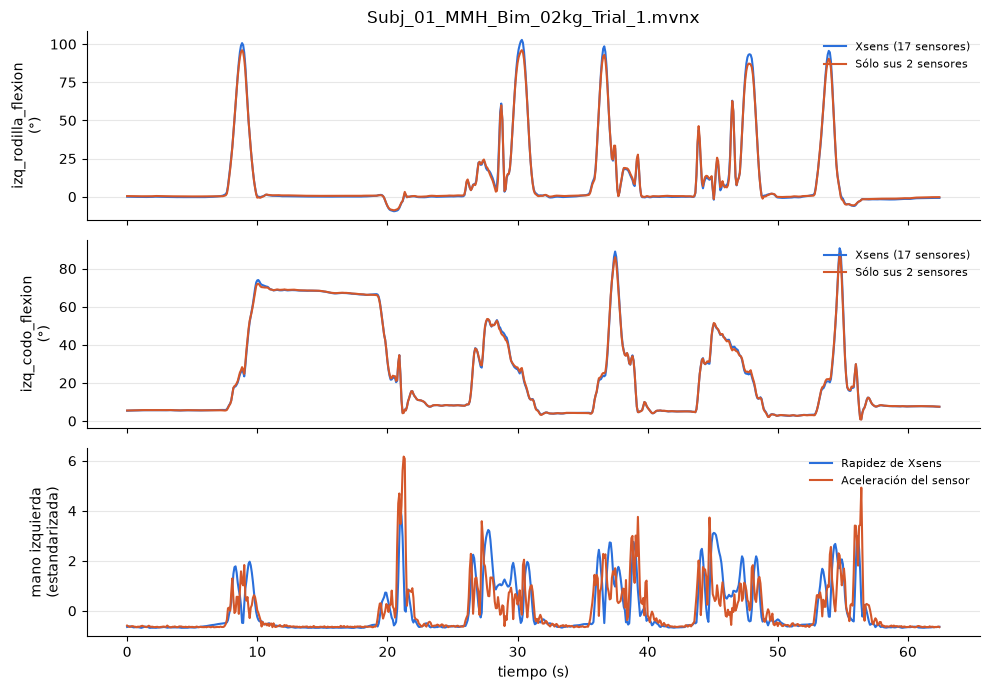

In [11]:
# Ejemplo: un ensayo bimanual del sujeto 1. Xsens (cuerpo completo) frente a los sensores solos.
r = trials[(trials["subject"] == 1) & (trials["conjunto"] == "bimanual")].iloc[0]
sl = slice(r.offset, r.offset + r.n_steps)
t = np.arange(r.n_steps) / TARGET_FS
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, var in zip(axes[:2], ("izq_rodilla_flexion", "izq_codo_flexion")):
    ax.plot(t, signals_raw[sl, CHANNELS.index(var)], color="#2a6fdb", lw=1.5, label="Xsens (17 sensores)")
    ax.plot(t, angles_sensors[sl, ANGLE_VARS.index(var)], color="#d4572a", lw=1.5, label="Sólo sus 2 sensores")
    ax.set(ylabel=f"{var}\n(°)")
z = lambda x: (x - x.mean()) / x.std()
axes[2].plot(t, z(signals_raw[sl, CHANNELS.index("izq_mano_rapidez")]), color="#2a6fdb", lw=1.5, label="Rapidez de Xsens")
axes[2].plot(t, z(hand_acc[sl, 0]), color="#d4572a", lw=1.5, label="Aceleración del sensor")
axes[2].set(ylabel="mano izquierda\n(estandarizada)", xlabel="tiempo (s)")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right", frameon=False, fontsize=8)
axes[0].set_title(f"{r.mvnx_file}")
plt.tight_layout()
plt.show()

# 5. Condiciones

Las tres series tienen las mismas 10 columnas, en el orden de `VARS_XSENS`; sólo cambia de dónde sale cada una.

In [12]:
def condition_signals(angles, hand):
    """Serie (instantes, 10) de una condición: ángulos de Xsens o de los sensores; rapidez de Xsens o aceleración del sensor."""
    out = signals_raw[:, [CHANNELS.index(v) for v in VARS_XSENS]].copy()
    names = list(VARS_XSENS)
    if angles == "sensores":
        for j, var in enumerate(ANGLE_VARS):
            out[:, VARS_XSENS.index(var)] = angles_sensors[:, j]
    if hand == "aceleracion":
        for j, var in enumerate(HAND_VARS):
            out[:, VARS_XSENS.index(var)] = hand_acc[:, j]
            names[VARS_XSENS.index(var)] = var.replace("rapidez", "aceleracion")
    return out, names


CONDITIONS = {}
for cond, angles, hand, desc in (("xsens", "xsens", "rapidez", "Xsens (17 sensores)"),
                                 ("angulos_sensores", "sensores", "rapidez", "Ángulos de los sensores + rapidez de Xsens"),
                                 ("sensores", "sensores", "aceleracion", "Sólo los 11 sensores")):
    signals, names = condition_signals(angles, hand)
    CONDITIONS[cond] = {"descripcion": desc, "signals": signals, "variables": names}
    assert not np.isnan(signals[cv_rows]).any()
display(pd.DataFrame({c: v["variables"] for c, v in CONDITIONS.items()}))

,xsens,angulos_sensores,sensores
0,izq_codo_flexion,izq_codo_flexion,izq_codo_flexion
1,izq_muneca_flexion,izq_muneca_flexion,izq_muneca_flexion
2,izq_cadera_flexion,izq_cadera_flexion,izq_cadera_flexion
3,izq_rodilla_flexion,izq_rodilla_flexion,izq_rodilla_flexion
4,der_codo_flexion,der_codo_flexion,der_codo_flexion
5,der_muneca_flexion,der_muneca_flexion,der_muneca_flexion
6,der_cadera_flexion,der_cadera_flexion,der_cadera_flexion
7,der_rodilla_flexion,der_rodilla_flexion,der_rodilla_flexion
8,izq_mano_rapidez,izq_mano_rapidez,izq_mano_aceleracion
9,der_mano_rapidez,der_mano_rapidez,der_mano_aceleracion


# 6. Random Forest

Las mismas 5 estadísticas por variable y el mismo RF del notebook 11, con el mismo LOSO. **Control:** con la condición `xsens` el resultado debe ser idéntico al del notebook 11 (`rf/EML.json`), porque el RF es determinista.

In [13]:
def eval_rf(cond):
    """F1 macro del Random Forest de una condición en cada ronda LOSO -> array (rondas,)."""
    path = RUN_DIR / "rf" / f"{cond}.json"
    if path.exists():
        res = json.loads(path.read_text())
    else:
        path.parent.mkdir(parents=True, exist_ok=True)
        X = window_stats(starts_of(sup_cv), CONDITIONS[cond]["signals"])
        y, subj = sup_cv["target"].to_numpy(), sup_cv["subject"].to_numpy()
        assert not np.isnan(X).any()
        t0, f1 = time.time(), {}
        for held_out in FOLDS:
            _, train_subjects = split_subjects(held_out)
            train, held = np.isin(subj, train_subjects), subj == held_out
            clf = RandomForestClassifier(**RF_PARAMS).fit(X[train], y[train])
            f1[str(held_out)] = f1_score(y[held], clf.predict(X[held]), average="macro")
        res = {"condicion": cond, "variables": CONDITIONS[cond]["variables"], "f1": f1, "minutos": (time.time() - t0) / 60}
        path.write_text(json.dumps(res))
    return np.array([res["f1"][str(s)] for s in FOLDS])


results = {cond: {"rf": eval_rf(cond)} for cond in CONDITIONS}
if not QUICK:   # control: la condición xsens reproduce el RF del notebook 11
    nb11_rf = json.loads((NB11_DIR / "rf" / "EML.json").read_text())["f1"]
    assert np.allclose(results["xsens"]["rf"], [nb11_rf[str(s)] for s in FOLDS]), "El RF de xsens no reproduce el del notebook 11"
for cond, r in results.items():
    log(f"RF · {cond} | F1 {r['rf'].mean():.3f}")

2026-11-05 17:13 | RF · xsens | F1 0.892
2026-11-05 17:13 | RF · angulos_sensores | F1 0.892
2026-11-05 17:13 | RF · sensores | F1 0.883


# 7. CPC-GRU + ajuste fino

El mismo modelo y procedimiento del notebook 11 (CPC sin etiquetas con negativos del mismo sujeto, después LP-FT), con la serie de cada condición. Dos diferencias:

- **El escalador** se ajusta con la serie de la condición (los sujetos de entrenamiento de cada ronda), porque las variables de los sensores tienen otra distribución.
- **La condición `xsens` no se reentrena:** se toman las 12 rondas de `EML` del notebook 11.

Cada ronda se guarda en `gru_ft/<condición>/` (≈ 4–7 min por ronda, ≈ 1 h por condición).

In [14]:
@dataclass
class CPCConfig:
    n_channels: int = 30
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2
    n_anchors: int = N_ANCHORS
    horizons: tuple = HORIZONS

    @property
    def z_dim(self):
        return self.enc_channels[-1]

    @property
    def c_dim(self):
        return self.ar_hidden_size


class CausalEncoder(nn.Module):
    """g_enc causal: 3 bloques Conv1d -> ReLU -> Dropout, relleno sólo a la izquierda. x: (B, canales, T) -> z: (B, 128, T)"""

    def __init__(self, cfg):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x):
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z


class CPCModel(nn.Module):
    """CPC con g_ar GRU: encoder + GRU + una W_k por horizonte; pérdida InfoNCE con negativos del batch."""

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)
        self.ar = nn.GRU(cfg.z_dim, cfg.c_dim, num_layers=cfg.ar_num_layers, dropout=cfg.ar_dropout, batch_first=True)
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in cfg.horizons])

    def encode(self, x):
        """x: (B, canales, T) -> z: (B, T, 128), c: (B, T, 256)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)[0]

    def info_nce(self, x):
        z, c = self.encode(x)
        lo, hi = max(1, z.shape[1] // 8), z.shape[1] - max(self.cfg.horizons)   # deja sitio para leer z_{t+12}
        target = torch.arange(len(x), device=x.device)
        losses = []
        for t in torch.randint(lo, hi, size=(self.cfg.n_anchors,)).tolist():
            for head, k in zip(self.heads, self.cfg.horizons):
                logits = head(c[:, t]) @ z[:, t + k].t()                         # (B, B): la diagonal es el positivo
                losses.append(F.cross_entropy(logits, target))
        return torch.stack(losses).mean()


class CPCClassifier(nn.Module):
    """Encoder y GRU de CPC + cabeza (LayerNorm, Dropout, Linear) sobre c_T, el contexto del último instante."""

    def __init__(self, cpc_model, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar = cpc_model.encoder, cpc_model.ar
        dim = cpc_model.cfg.c_dim
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def features(self, x):
        return self.ar(self.encoder(x).transpose(1, 2))[0][:, -1]

    def forward(self, x):
        return self.head(self.features(x))


def build_cpc(n_channels, seed=SEED):
    torch.manual_seed(seed)
    return CPCModel(CPCConfig(n_channels=n_channels)).to(DEVICE)

In [15]:
# ----------------------------- Serie escalada de la ronda, con la serie de la condición -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (ventanas, variables del subconjunto, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


def prepare_round(held_out, cond):
    """Escalador de la ronda (ajustado con la serie de la condición) y serie escalada en el dispositivo."""
    global S_T
    inner_val, train_subjects, sets, n_steps = make_sets(held_out)
    signals = CONDITIONS[cond]["signals"]
    scaler = fit_scaler(train_subjects, signals=signals, binary=[])      # en EML no hay variables binarias
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler, signals).T)).to(DEVICE)
    return {"held_out": held_out, "inner_val": inner_val, "train_subjects": train_subjects, "sets": sets,
            "n_steps": n_steps, "n_channels": signals.shape[1], "scaler": scaler}


@torch.no_grad()
def batched(fn, starts, batch=512):
    return torch.cat([fn(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


@torch.no_grad()
def predict(model, starts):
    model.eval()
    return batched(model, starts).argmax(1).cpu().numpy()


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


# ----------------------------- Preentrenamiento CPC (sin etiquetas) -----------------------------
class SameSubjectSampler:
    """Batches de CPC: ventanas al azar de UN solo sujeto, así los negativos de InfoNCE son de la misma persona."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()                                         # sujetos con más datos salen más seguido

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def probe_val_f1(model, rnd):
    """F1 en la validación interna de una sonda lineal (C = 1) sobre c_T. Decide la parada temprana de CPC."""
    model.eval()
    rep = lambda part: batched(lambda x: model.encode(x)[1][:, -1], rnd["sets"][part]["starts"]).float().cpu().numpy()
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    probe.fit(rep("probe_train"), rnd["sets"]["probe_train"]["y"])
    return f1_score(rnd["sets"]["val"]["y"], probe.predict(rep("val")), average="macro")


def train_cpc(rnd, seed=SEED):
    t0 = time.time()
    model = build_cpc(rnd["n_channels"], seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler(rnd["train_subjects"], seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0
    for epoch in range(1, CPC_EPOCHS + 1):
        model.train()
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(get_windows(sampler.batch()))             # pérdida contrastiva: no usa etiquetas
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            f1_val = probe_val_f1(model, rnd)
            if f1_val > best["f1"] + 1e-4:
                best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


# ----------------------------- LP-FT (con etiquetas) -----------------------------
def linear_probe_head(model, sets, seed):
    """Etapa LP: entrena sólo la cabeza con el encoder y la GRU congelados."""
    model.eval()
    X_tr, X_val = batched(model.features, sets["ft_train"]["starts"]), batched(model.features, sets["val"]["starts"])
    y_tr = torch.as_tensor(np.array(sets["ft_train"]["y"]), device=DEVICE)
    weights = class_weights(sets["ft_train"]["y"])
    opt = torch.optim.AdamW(model.head.parameters(), lr=LP_LR, weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    best, bad = {"f1": -1.0, "state": copy.deepcopy(model.head.state_dict())}, 0
    for epoch in range(1, LP_EPOCHS + 1):
        model.head.train()
        order = rng.permutation(len(y_tr))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = torch.as_tensor(order[s:s + FINETUNE_BATCH], device=DEVICE)
            loss = F.cross_entropy(model.head(X_tr[idx]), y_tr[idx], weight=weights)
            opt.zero_grad(); loss.backward(); opt.step()
        model.head.eval()
        with torch.no_grad():
            f1_val = f1_score(sets["val"]["y"], model.head(X_val).argmax(1).cpu().numpy(), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "state": copy.deepcopy(model.head.state_dict())}, 0
        else:
            bad += 1
        if bad >= LP_PATIENCE:
            break
    model.head.load_state_dict(best["state"])
    return best["f1"]


def finetune(cpc_model, sets, seed=SEED):
    """LP-FT: la cabeza de LP es el punto de partida (época 0) y después se ajusta toda la red."""
    t0 = time.time()
    torch.manual_seed(seed)
    model = CPCClassifier(cpc_model).to(DEVICE)
    best = {"f1": linear_probe_head(model, sets, seed), "epoch": 0, "state": copy.deepcopy(model.state_dict())}
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    weights = class_weights(train["y"])
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng, bad = np.random.default_rng(seed), 0
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FT_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}

In [16]:
def run_gru_round(cond, held_out):
    """Una ronda de CPC-GRU + LP-FT con la serie de `cond`. Se guarda al terminar y se carga si ya existe."""
    path = RUN_DIR / "gru_ft" / cond / f"ronda_s{held_out:02d}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    rnd = prepare_round(held_out, cond)
    cpc_model, info_cpc = train_cpc(rnd)
    cpc_state = copy.deepcopy(cpc_model.state_dict())                        # el ajuste fino modifica la red en su lugar
    model, info_ft = finetune(cpc_model, rnd["sets"])
    y, pred = rnd["sets"]["held"]["y"], predict(model, rnd["sets"]["held"]["starts"])
    result = {"held_out": held_out, "inner_val": rnd["inner_val"], "condicion": cond, "variables": CONDITIONS[cond]["variables"],
              "f1": f1_score(y, pred, average="macro"), "cpc": info_cpc, "ajuste_fino": info_ft,
              "minutos": info_cpc["minutes"] + info_ft["minutes"], "scaler": rnd["scaler"],
              "index": rnd["sets"]["held"]["index"].tolist(), "y": y.tolist(), "pred": pred.tolist()}
    torch.save({"cpc": cpc_state, "ajuste_fino": model.state_dict(), "variables": result["variables"]}, path.with_suffix(".pt"))
    path.write_text(json.dumps(result))
    log(f"GRU · {cond} · sujeto {held_out:2d} | F1 {result['f1']:.3f} | {result['minutos']:.1f} min")
    del cpc_model, model
    return result


def eval_gru(cond):
    """F1 macro de CPC-GRU + LP-FT en cada ronda -> array (rondas,). Con `xsens`, las rondas de EML del notebook 11."""
    if cond == "xsens":
        return np.array([json.loads((NB11_DIR / "gru_ft" / "EML" / f"ronda_s{s:02d}.json").read_text())["f1"] for s in FOLDS])
    return np.array([run_gru_round(cond, s)["f1"] for s in FOLDS])


for cond in CONDITIONS:
    results[cond]["gru"] = eval_gru(cond)
    log(f"GRU · {cond} | F1 {results[cond]['gru'].mean():.3f}")

2026-11-05 17:13 | GRU · xsens | F1 0.873
2026-11-05 17:18 | GRU · angulos_sensores · sujeto  1 | F1 0.882 | 5.2 min
2026-11-05 17:22 | GRU · angulos_sensores · sujeto  2 | F1 0.793 | 3.9 min
2026-11-05 17:27 | GRU · angulos_sensores · sujeto  3 | F1 0.842 | 4.5 min
2026-11-05 17:32 | GRU · angulos_sensores · sujeto  4 | F1 0.901 | 4.9 min
2026-11-05 17:38 | GRU · angulos_sensores · sujeto  5 | F1 0.887 | 6.3 min
2026-11-05 17:42 | GRU · angulos_sensores · sujeto  6 | F1 0.904 | 3.7 min
2026-11-05 17:47 | GRU · angulos_sensores · sujeto  7 | F1 0.887 | 5.7 min
2026-11-05 17:52 | GRU · angulos_sensores · sujeto  8 | F1 0.865 | 4.2 min
2026-11-05 17:59 | GRU · angulos_sensores · sujeto  9 | F1 0.894 | 7.6 min
2026-11-05 18:04 | GRU · angulos_sensores · sujeto 10 | F1 0.882 | 5.2 min
2026-11-05 18:09 | GRU · angulos_sensores · sujeto 11 | F1 0.885 | 4.3 min
2026-11-05 18:14 | GRU · angulos_sensores · sujeto 12 | F1 0.889 | 4.9 min
2026-11-05 18:14 | GRU · angulos_sensores | F1 0.876
2026-

# 8. Resultado

Para cada modelo: F1 macro medio, desviación y peor sujeto de cada condición, y la comparación por sujeto contra `xsens`: diferencia de medias, en cuántos sujetos mejora y la prueba de Wilcoxon pareada.

In [17]:
def paired(a, b):
    """Comparación por sujeto de `a` contra `b`: diferencia de medias, sujetos en que mejora y p de Wilcoxon."""
    d = np.asarray(a) - np.asarray(b)
    p = wilcoxon(a, b).pvalue if np.any(d != 0) and len(d) > 1 else np.nan
    return {"Δ vs. xsens": d.mean(), "mejora en": f"{(d > 0).sum()}/{len(d)}", "p (Wilcoxon)": p}


rows = []
for model in ("rf", "gru"):
    for cond, r in results.items():
        s = summarize(r[model])
        row = {"modelo": "Random Forest" if model == "rf" else "CPC-GRU + ajuste fino", "condición": cond,
               "descripción": CONDITIONS[cond]["descripcion"], "F1": s["f1"], "desv.": s["desv"], "peor": s["peor"]}
        if cond != "xsens":
            row.update(paired(r[model], results["xsens"][model]))
        rows.append(row)
summary = pd.DataFrame(rows).set_index(["modelo", "condición"])
display(summary.style.format({"F1": "{:.3f}", "desv.": "{:.3f}", "peor": "{:.3f}", "Δ vs. xsens": "{:+.3f}",
                              "p (Wilcoxon)": "{:.3f}"}, na_rep="—"))

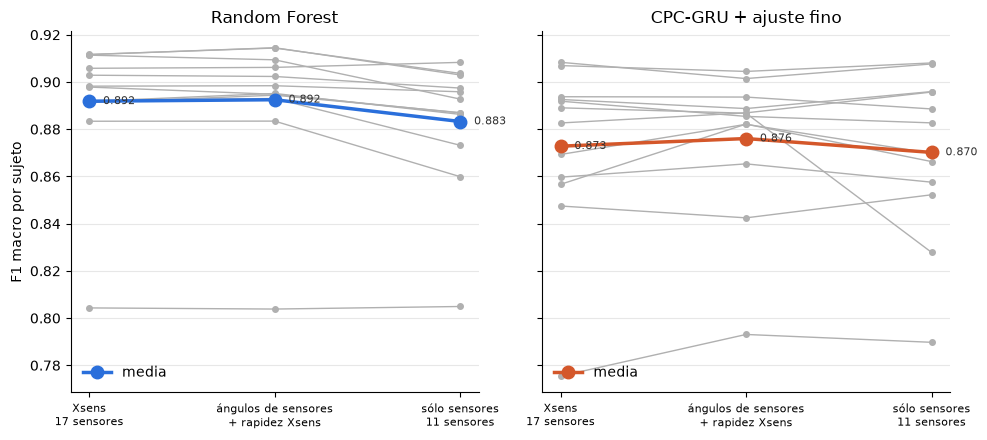

In [18]:
# F1 de cada sujeto en las tres condiciones: cada línea gris es un sujeto; los puntos de color, la media
COLORS = {"rf": "#2a6fdb", "gru": "#d4572a"}
TITLE = {"rf": "Random Forest", "gru": "CPC-GRU + ajuste fino"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
x = np.arange(len(CONDITIONS))
for ax, model in zip(axes, ("rf", "gru")):
    per_subject = np.array([results[c][model] for c in CONDITIONS])          # (condiciones, sujetos)
    for j, s in enumerate(FOLDS):
        ax.plot(x, per_subject[:, j], color="#b0b0b0", lw=1, marker="o", ms=4, zorder=1)
    means = per_subject.mean(axis=1)
    ax.plot(x, means, color=COLORS[model], lw=2.5, marker="o", ms=9, zorder=2, label="media")
    for xi, m in zip(x, means):
        ax.annotate(f"{m:.3f}", (xi, m), xytext=(10, 0), textcoords="offset points", va="center", fontsize=8, color="#333")
    ax.set_xticks(x, ["Xsens\n17 sensores", "ángulos de sensores\n+ rapidez Xsens", "sólo sensores\n11 sensores"], fontsize=8)
    ax.set_title(TITLE[model])
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower left", frameon=False)
axes[0].set_ylabel("F1 macro por sujeto")
plt.tight_layout()
plt.show()

# 9. Conclusiones

**Respuesta a la pregunta.** Sí: las variables mínimas calculadas **sólo con los 11 sensores** reconocen la actividad prácticamente igual que las de Xsens con 17 sensores. La GRU no pierde desempeño (0.870 frente a 0.873, sin diferencia significativa). El RF pierde 0.009 (0.883 frente a 0.892), una caída pequeña pero consistente, y se debe sólo a la variable de la mano, no a los ángulos.

| Modelo | Xsens (17 sensores) | Ángulos de los sensores + rapidez de Xsens | Sólo los 11 sensores |
|---|---|---|---|
| Random Forest | 0.892 | 0.892 (+0.001, p = 0.34) | **0.883** (−0.009, mejora en 2/12, p = 0.003) |
| CPC-GRU + ajuste fino | 0.873 | 0.876 (+0.003, p = 0.68) | **0.870** (−0.003, mejora en 7/12, p = 0.68) |

*Diferencias contra `xsens`, prueba de Wilcoxon pareada por sujeto. Referencia con las 30 variables: RF 0.894 y GRU 0.878.*

**1. Los ángulos no necesitan el modelo del cuerpo completo.**
- El modelo de Xsens sí corrige las orientaciones de los sensores. La rotación sensor → segmento varía dentro de cada ensayo (p95) ≈ 0.2° en las manos, ≈ 0.7–1.1° en brazos y antebrazos, y ≈ 2.8–4.1° en la pelvis, los muslos y las piernas (sección 4.1).
- Por eso los ángulos de los sensores se alejan poco de los de Xsens en codos y muñecas (error p95 ≈ 0.6–1.0°) y algo más en caderas y rodillas (p95 ≈ 3.5–4.5°, con picos de ≈ 20°). Aun así, la correlación es ≥ 0.997 en los 8 ángulos.
- Ese error **no cambia el reconocimiento**: con los ángulos de los sensores, el F1 es igual en los dos modelos (+0.001 y +0.003). Un error de pocos grados es pequeño frente a lo que distingue las actividades: el ejemplo de la sección 4.1 muestra que la forma de las curvas se conserva.

**2. Lo único que cuesta es cambiar la rapidez de la mano por su aceleración, y sólo al RF.**
- **RF:** la condición `sensores` pierde 0.009 frente a `angulos_sensores` en 10 de 12 sujetos (p = 0.002). La caída se concentra en los sujetos 3, 9 y 10 (≈ −0.02).
- **GRU:** no hay pérdida (mejora en 7 de 12 sujetos, p = 0.68). La caída aparente viene de un solo sujeto (sujeto 7: 0.889 → 0.828); sin él, la media incluso sube. Con una sola semilla, esa caída aislada puede ser ruido, como pasó con el sujeto 8 en el notebook 11.
- **Por qué afecta más al RF (hipótesis):**
  - La aceleración y la rapidez se parecen sólo en parte (correlación 0.67). La aceleración marca los cambios bruscos, pero no ve un movimiento a velocidad constante.
  - El RF sólo ve 5 estadísticas por ventana, así que pierde esa información.
  - La GRU recorre la ventana paso a paso y puede "integrar" la aceleración, recuperando parte de lo que la rapidez daba directamente.
  - Coincide con que, en la GRU, la actividad que más baja es caminar (W: F1 0.933 → 0.915), donde la mano se traslada con el cuerpo a velocidad casi constante.

**3. Implicación práctica.** Un sistema de **11 IMU** (pelvis y, de cada lado, brazo, antebrazo, mano, muslo y pierna) que calcule 8 ángulos articulares y la aceleración de las manos reconoce las 7 actividades con F1 ≈ 0.87–0.88. Frente al traje completo con las 30 variables, eso es ≈ 0.01 menos, con 6 sensores menos y sin la reconstrucción de posiciones del cuerpo completo.

**4. Cuál modelo conviene con 11 sensores.**
- Con las variables de Xsens, el RF es mejor que la GRU (0.892 frente a 0.873).
- Con las variables de los sensores, la ventaja se reduce a 0.013 (0.883 frente a 0.870) y el peor sujeto queda en 0.805 y 0.790.
- El RF sigue siendo igual o mejor, pero la GRU es más robusta al cambio de la variable de la mano.

**Limitaciones que se deben declarar:**

- **`sensorOrientation` no es la señal cruda.** Es la orientación que estima Xsens para cada sensor (giroscopio, acelerómetro y magnetómetro fusionados). El MVNX no trae el giroscopio ni el acelerómetro crudos, así que no se puede probar otro algoritmo de fusión, ni descartar que esa orientación ya use información de otros sensores. El resultado vale para IMU con una fusión de calidad comparable a la de Xsens.
- **Calibración ideal.** La rotación sensor → segmento se estima con el modelo de Xsens y en cada ensayo. Un sistema real la estimaría una vez (postura N) y la usaría en toda la sesión; si un sensor se mueve, el error crece.
- **Una sola semilla por condición en la GRU** (ruido de ±0.01). La caída del sujeto 7 con la GRU habría que confirmarla con más semillas.
- **El subconjunto se eligió con los mismos 12 sujetos.** La estimación honesta será en los sujetos 13 y 14.

**Siguientes pasos posibles:**

- **Recuperar la información de traslación sin sensores extra.** Por ejemplo, agregar la aceleración de la pelvis (el sensor ya está), o la rapidez de la mano integrada dentro de cada ventana de 4 s, donde la deriva todavía es pequeña. Esto apunta a la pérdida del RF.
- **Evaluar el sistema de 11 sensores en los sujetos 13 y 14**, junto con la evaluación final del proyecto.

**Prueba que se puede hacer después: sensibilidad al ruido.** Un sistema de IMU más barato, o con otra fusión, tendría ángulos con más error que los de este notebook. Para saber cuánto error tolera el modelo, se puede agregar a los ángulos de la condición `sensores` un error simulado y medir el F1 (con el RF, que es rápido; la GRU sólo en el punto de interés):

- **Ruido blanco** de 2°, 5° y 10° (desviación estándar), que representa el ruido de medición.
- **Deriva lenta**, como un paseo aleatorio que crece a lo largo del ensayo (p. ej. 1°, 3° y 5° por minuto), que representa el error de la orientación sin magnetómetro.
- **Error de calibración** fijo por ensayo (p. ej. un desfase de 5° o 10°), que representa un sensor mal colocado o que se movió.

El resultado sería una curva de F1 contra error, que dice qué precisión debe tener un sistema en planta para conservar el desempeño. Los resultados de este notebook dan un primer punto de esa curva: errores de ≈ 1–4° (p95) en los ángulos no cambian el F1.